#E-commerce Landing Page A/B Test Analysis

In [1]:
'''A Statistical analysis of a company landing page with the new page checking that the new page is performing well or not and improving the converison rates'''

'A Statistical analysis of a company landing page with the new page checking that the new page is performing well or not and improving the converison rates'

Project Objective

An e-commerce company redesigned its landing page and wants to know whether the new page converts more visitors into buyers than the old page.

The objective of this project is to:

Clean and validate the experiment data (check for missing values, duplicate users and visitors who saw the wrong page).
Compare the conversion rates of the control group (old page) and the treatment group (new page).
Test whether the observed difference is statistically significant using a two-proportion Z-test.
Quantify the uncertainty with a 95% confidence interval.
Give a clear, data-backed recommendation on whether to launch the new page.

In [2]:
#Importing Libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
#Data Ingestion
df = pd.read_csv('/content/ab_data.csv')
df

,user_id,timestamp,group,landing_page,converted
0,851104,2017-01-21 22:11:48.556739,control,old_page,0
1,804228,2017-01-12 08:01:45.159739,control,old_page,0
2,661590,2017-01-11 16:55:06.154213,treatment,new_page,0
3,853541,2017-01-08 18:28:03.143765,treatment,new_page,0
4,864975,2017-01-21 01:52:26.210827,control,old_page,1
...,...,...,...,...,...
294473,751197,2017-01-03 22:28:38.630509,control,old_page,0
294474,945152,2017-01-12 00:51:57.078372,control,old_page,0
294475,734608,2017-01-22 11:45:03.439544,control,old_page,0
294476,697314,2017-01-15 01:20:28.957438,control,old_page,0


The dataset is about an E-commerce A/B Testing Experiment, where a company wants to find out whether a new website landing page performs better than its existing landing page.

#About the columns in the dataset

Column	       |      Business meaning\
user_id	       :    Unique identification of a customer\
timestamp	      :   Date and time when the experiment recorded the user's visit\
group	  :   Whether the customer belongs to control or treatment\
landing_page	  :  Which website version the customer received\
converted	 :  Whether the customer completed the desired conversion

0 = Customer visited but did not complete a purchase.



1 = Customer completed a purchase.

#Data Preprocessing

In [4]:
df.shape

(294478, 5)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 294478 entries, 0 to 294477
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   user_id       294478 non-null  int64 
 1   timestamp     294478 non-null  object
 2   group         294478 non-null  object
 3   landing_page  294478 non-null  object
 4   converted     294478 non-null  int64 
dtypes: int64(2), object(3)
memory usage: 11.2+ MB


In [6]:
df.isna().sum()

,0
user_id,0
timestamp,0
group,0
landing_page,0
converted,0


In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df['converted'].value_counts()

,count
converted,
0,259241
1,35237


In [9]:
df['group'].unique()

array(['control', 'treatment'], dtype=object)

In [10]:
df['landing_page'].unique()

array(['old_page', 'new_page'], dtype=object)

In [11]:
pd.crosstab(df['group'], df['landing_page'])

landing_page,new_page,old_page
group,,
control,1928,145274
treatment,145311,1965


In [12]:
df['group'].value_counts()

,count
group,
treatment,147276
control,147202


In [13]:
print('Total Record :',df.shape[0])
print('Unique Users:',df['user_id'].nunique())
print('Duplicated Users :',df['user_id'].duplicated().sum())

print(df['user_id'].value_counts().head(10))

Total Record : 294478
Unique Users: 290584
Duplicated Users : 3894
user_id
752737    2
781280    2
767913    2
886060    2
731779    2
827432    2
677313    2
756804    2
671874    2
741541    2
Name: count, dtype: int64


In [14]:
df['timestamp'] = pd.to_datetime(df['timestamp'])

In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 294478 entries, 0 to 294477
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   user_id       294478 non-null  int64         
 1   timestamp     294478 non-null  datetime64[ns]
 2   group         294478 non-null  object        
 3   landing_page  294478 non-null  object        
 4   converted     294478 non-null  int64         
dtypes: datetime64[ns](1), int64(2), object(2)
memory usage: 11.2+ MB


In [16]:
duplicated_users = df[df['user_id'].duplicated(keep=False)].sort_values('user_id')
print(duplicated_users)

        user_id                  timestamp      group landing_page  converted
213114   630052 2017-01-07 12:25:54.089486  treatment     old_page          1
230259   630052 2017-01-17 01:16:05.208766  treatment     new_page          0
251762   630126 2017-01-19 17:16:00.280440  treatment     new_page          0
22513    630126 2017-01-14 13:35:54.778695  treatment     old_page          0
11792    630137 2017-01-22 14:59:22.051308    control     new_page          0
...         ...                        ...        ...          ...        ...
99479    945703 2017-01-18 06:39:31.294688    control     old_page          0
186960   945797 2017-01-13 17:23:21.750962    control     old_page          0
40370    945797 2017-01-11 03:04:49.433736    control     new_page          1
165143   945971 2017-01-16 10:09:18.383183    control     old_page          0
131756   945971 2017-01-22 12:43:54.087275    control     new_page          0

[7788 rows x 5 columns]


In [17]:
user_check = df.groupby('user_id').agg(
    total_records=('user_id', 'count'),
    unique_groups=('group', 'nunique'),
    unique_pages=('landing_page', 'nunique'),
    unique_conversions=('converted', 'nunique')
)

print("Users with multiple groups:",
      (user_check['unique_groups'] > 1).sum())

print("Users with multiple landing pages:",
      (user_check['unique_pages'] > 1).sum())

print("Users with multiple conversion outcomes:",
      (user_check['unique_conversions'] > 1).sum())

print("Users with more than one record:",
      (user_check['total_records'] > 1).sum())

Users with multiple groups: 1895
Users with multiple landing pages: 1998
Users with multiple conversion outcomes: 864
Users with more than one record: 3894


In [18]:
valid_records = df[
    ((df['group'] == 'control') & (df['landing_page'] == 'old_page')) | ((df['group'] == 'treatment') & (df['landing_page'] == 'new_page'))
]

print('Original Records : ', len(df))
print('Consistent Records :', len(valid_records))
print('Removed Records:', len(df) - len(valid_records))

print("Unique users:", valid_records['user_id'].nunique())
print("Repeated user records:",
      valid_records['user_id'].duplicated().sum())

Original Records :  294478
Consistent Records : 290585
Removed Records: 3893
Unique users: 290584
Repeated user records: 1


In [19]:
remaining_duplicates = valid_records[valid_records['user_id'].duplicated(keep=False)].value_counts('user_id')

In [20]:
remaining_duplicates

,count
user_id,
773192,2


In [21]:
valid_records[
    valid_records['user_id'] == 773192
]

,user_id,timestamp,group,landing_page,converted
1899,773192,2017-01-09 05:37:58.781806,treatment,new_page,0
2893,773192,2017-01-14 02:55:59.590927,treatment,new_page,0


In [22]:
df_clean = valid_records.drop_duplicates(keep='first',subset='user_id').copy()

print('Orignal Users',df_clean.shape)
print('Unique Users',df_clean['user_id'].nunique())
print('Duplicated Users',df_clean['user_id'].duplicated().sum())


Orignal Users (290584, 5)
Unique Users 290584
Duplicated Users 0


#Exploratory Data Analysis

In [35]:
total_user = len(df_clean)

conversion = df_clean['converted'].sum()

conversion_rate = (conversion / total_user) * 100

print('Total User:',total_user)
print('Conversion',conversion)
print('Conversion %',conversion_rate)

Total User: 290584
Conversion 34753
Conversion % 11.959708724499627


In [24]:
total_users = df_clean.shape[0]

total_conversions = df_clean['converted'].sum()

overall_conversion_rate = (
    total_conversions / total_users
) * 100

print("Total Users:", total_users)
print("Total Conversions:", total_conversions)
print("Conversion Rate:", round(overall_conversion_rate, 2), "%")

Total Users: 290584
Total Conversions: 34753
Conversion Rate: 11.96 %


In [25]:
df_clean.groupby('group').count()

,user_id,timestamp,landing_page,converted
group,,,,
control,145274,145274,145274,145274
treatment,145310,145310,145310,145310


In [26]:
df_clean.columns

Index(['user_id', 'timestamp', 'group', 'landing_page', 'converted'], dtype='object')

In [27]:
group_analysis = df_clean.groupby('group').agg(
    total_users=('user_id', 'count'),
    converted=('converted', 'sum'),
    conversion_rate=('converted', 'mean')
)

group_analysis['conversion_rate'] *= 100

print(group_analysis)

           total_users  converted  conversion_rate
group                                             
control         145274      17489        12.038630
treatment       145310      17264        11.880807


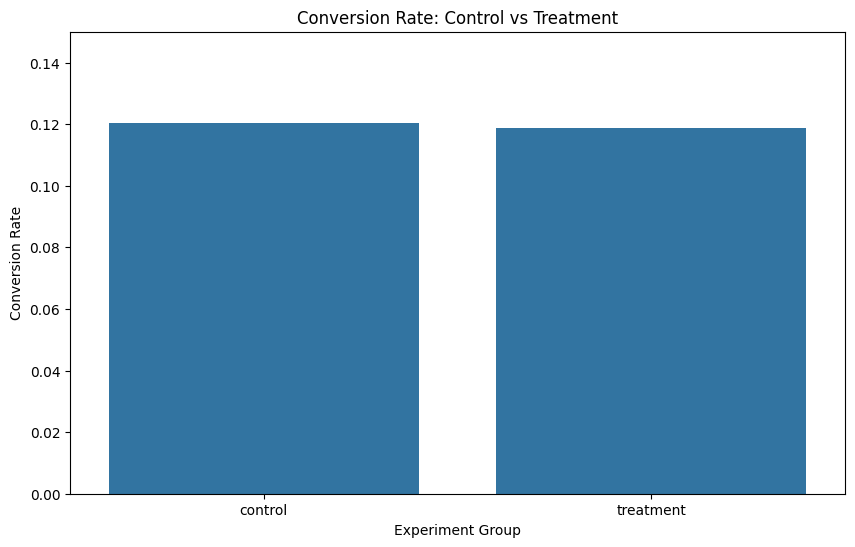

In [28]:
plt.figure(figsize=(10,6))
sns.barplot(data=df_clean,x='group',y='converted',estimator='mean',errorbar=None)

plt.title('Conversion Rate: Control vs Treatment')
plt.xlabel('Experiment Group')
plt.ylabel('Conversion Rate')
plt.ylim(0, 0.15)

plt.show()

Z_test : A two-proportion Z-test (also called a two-sample Z-test for proportions) is a statistical hypothesis test used to determine if there is a significant difference between the proportions of two independent groups

We are conducting a Two Propotional Z-Test :\
H0 = Control Conversion Rate = Treatment Conversion Rate
H1 = Control Conversion Rate != Treatment Conversion Rate

In [29]:
control = df_clean[df_clean['group']=='control']
treatment = df_clean[df_clean['group']=='treatment']

n_control = len(control)
n_treatment = len(treatment)

x_control = control['converted'].sum()
x_treatment = treatment['converted'].sum()

print('Control Users:',n_control)
print('Treatment Users:',n_treatment)

print('Control Conversion:',x_control)
print('Treatment Conversion:',x_treatment)

Control Users: 145274
Treatment Users: 145310
Control Conversion: 17489
Treatment Conversion: 17264


In [30]:
print(df_clean.groupby('group').agg(
    total_users=('user_id', 'count'),
    conversions=('converted', 'sum')
))

           total_users  conversions
group                              
control         145274        17489
treatment       145310        17264


In [36]:
from scipy.stats import norm

#Individual Propotions : Propotion of conversion rates of both the treatment and control pages
p1 = x_control/n_control
p2 = x_treatment/n_treatment

#Pooled Propotions : It is a combined propotion assuming the equal propotion of H0
pooled_p = (x_control + x_treatment) / (n_control + n_treatment)

#Standard Error : Standard Error assumes how much difference between assumend sample propotion varies due to sampling
se = np.sqrt(pooled_p * (1-pooled_p)* (1/n_control + 1/n_treatment))

#Z_Score : It standardize the observed difference by dividing it by the standard error
Z_score = (p1-p2)/se

#P_value : The p-value tells us whether we have sufficient statistical evidence of a difference.
p_value = 2 * norm.sf(abs(Z_score))

print('Controlled Rate',p1)
print('Treatment Rate',p2)
print('Pooled Propotion',pooled_p)
print('Standard Error',se)
print('Z Score',Z_score)
print('p_value',p_value)

Controlled Rate 0.1203863045004612
Treatment Rate 0.11880806551510564
Pooled Propotion 0.11959708724499628
Standard Error 0.0012039132295014454
Z Score 1.3109241984234394
p_value 0.18988337448195103


In [37]:
alpha = 0.05

if p_value < alpha:
  print('Reject the H0')
else:
  print('Fail to reject the H0')

Fail to reject the H0


In [38]:
#Calculating the Confidence Interval

difference = p1-p2

se_ci = np.sqrt((p1 * (1-p1)/n_control) + (p2*(1-p2)/n_treatment))

lb = difference - 1.96 * se_ci
ub = difference + 1.96 * se_ci

print('Difference',difference)
print('Lower Bound',lb)
print('Upper Bound',ub)

Difference 0.0015782389853555567
Lower Bound -0.0007814256337327326
Upper Bound 0.003937903604443846


##Conclusion and Interpretation

**Conclusion:** The control group (old page) converted at 12.04% and the treatment group (new page) at 11.88%, a difference of about 0.16 percentage points. The two-proportion Z-test gave a Z-score of about 1.31 and a p-value of about 0.19, which is greater than the significance level of 0.05. So we **fail to reject the null hypothesis**. The 95% confidence interval for the difference (control − treatment) is roughly −0.08 to +0.39 percentage points. It includes zero, which agrees with the test result.

**Interpretation:**
- There is no statistically significant evidence that the new landing page changes the conversion rate. The small difference we observed could easily be due to random variation.
- The experiment did not provide sufficient statistical evidence that the new landing page improves conversion compared with the old page.
- Failing to reject H0 does not prove the two pages are identical. It only means this experiment did not find enough evidence of a difference.

**Business recommendation:** Do not roll out the new landing page expecting higher conversions. The old page performs at least as well. The company should only switch if the new design has other benefits, such as lower cost, easier maintenance or better branding. If a smaller improvement still matters to the business, run a longer test with more traffic.

**Data note:** Before the analysis, 3,893 records (about 1.3%) were removed because the group did not match the landing page shown, and one repeated user record was dropped. After cleaning, there were 290,584 unique users, split almost evenly between the two groups.'''